# Explaining the final LightGBM model

This notebook fits one LightGBM model using all cleaned training rows and the frozen no-rainfall feature set. It explains a fixed random sample of 5,000 training rows with TreeExplainer. It does not load or use any test or Imelda data.

## 1. Fit once and calculate SHAP values

The model uses the saved LightGBM settings: seed 42, 300 trees, learning rate 0.1. Numeric scaling and land-cover one-hot encoding are fitted on all cleaned training rows. `rainfall_inches` is excluded as specified by `reports/final_setup.csv`; the saved cutoff is used only to label example predictions.

In [1]:
import sys
from pathlib import Path

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project root.")
sys.path.insert(0, str(project_root))

import pandas as pd
from IPython.display import Image, display

from src.explain import (
    EXAMPLES_PATH,
    FIGURES_DIR,
    IMPORTANCE_PATH,
    run_shap_analysis,
)

result = run_shap_analysis()
print(f"Fitted rows: {result.row_count:,}")
print(f"Explained sample: {result.sample_size:,} rows (seed 42)")
print(f"Frozen cutoff: {result.cutoff:.2f}")

C:\Users\ssaifudd\Downloads\AI-Flood Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fitting lightgbm_no_rain once on 66,514 training rows.


Computing TreeExplainer SHAP values for 5,000 sampled rows.


Saved feature ranking to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\shap_feature_importance.csv
Saved example rows to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\shap_examples.csv
Saved 8 figures under C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures
Fitted rows: 66,514
Explained sample: 5,000 rows (seed 42)
Frozen cutoff: 0.50


**My observations:** The model used 66,514 cleaned training rows, and SHAP used a fixed 5,000-row sample with seed 42. Rainfall was excluded, and the saved 0.50 cutoff was used only to label the example predictions.

## 2. Global feature importance

The table compares mean absolute SHAP values with LightGBM's built-in split-count importance. The bar plot shows the SHAP ranking. These are model-importance measures, not evidence that a feature causes flooding.

,feature,mean_abs_shap,shap_rank,lightgbm_split_importance,lightgbm_split_rank
0,elevation_m,1.329801,1,2554,2
1,paved_pct,0.723200,2,2745,1
2,slope_degrees,0.653920,3,1503,4
3,"land cover type: Developed, Low Intensity",0.192739,4,169,5
4,distance_to_bayou_m,0.152670,5,1640,3
5,"land cover type: Developed, Open Space",0.126350,6,121,8
6,"land cover type: Developed, Medium Intensity",0.067090,7,138,6
7,"land cover type: Developed, High Intensity",0.058367,8,130,7


Spearman rank correlation: 0.833; top-three features shared: 2/3.


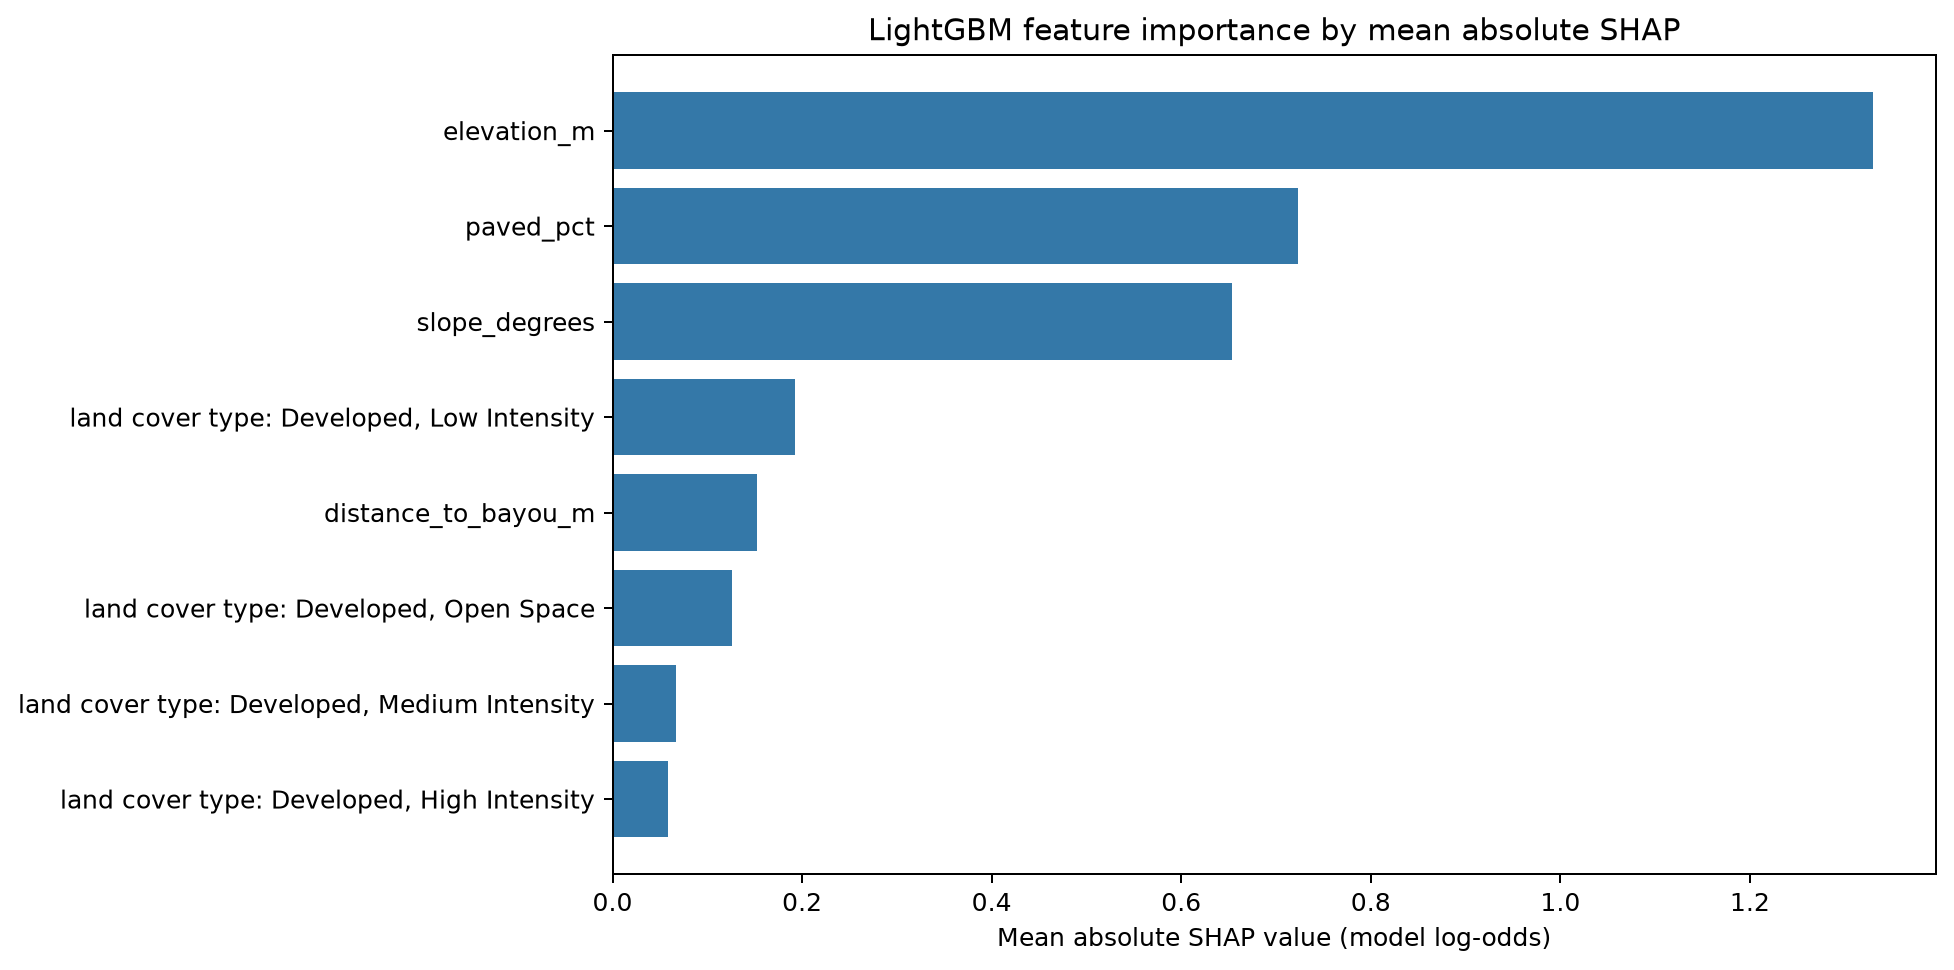

In [2]:
display(result.importance)
print(
    f"Spearman rank correlation: {result.rank_correlation:.3f}; "
    f"top-three features shared: {result.top_three_overlap}/3."
)
display(Image(filename=str(FIGURES_DIR / "shap_lightgbm_mean_abs.png")))

**My observations:** SHAP ranked elevation first (1.330), paved share second (0.723), and slope third (0.654). Built-in split importance ranked paved share first, elevation second, and distance to bayou third. The rankings partly agree: their Spearman correlation is 0.833 and they share 2 of their top 3 features.

## 3. SHAP summary and dependence plots

The beeswarm shows how each feature's values relate to its SHAP contribution across the sample. The dependence plots show the model's learned response for elevation, distance to a bayou, and slope.

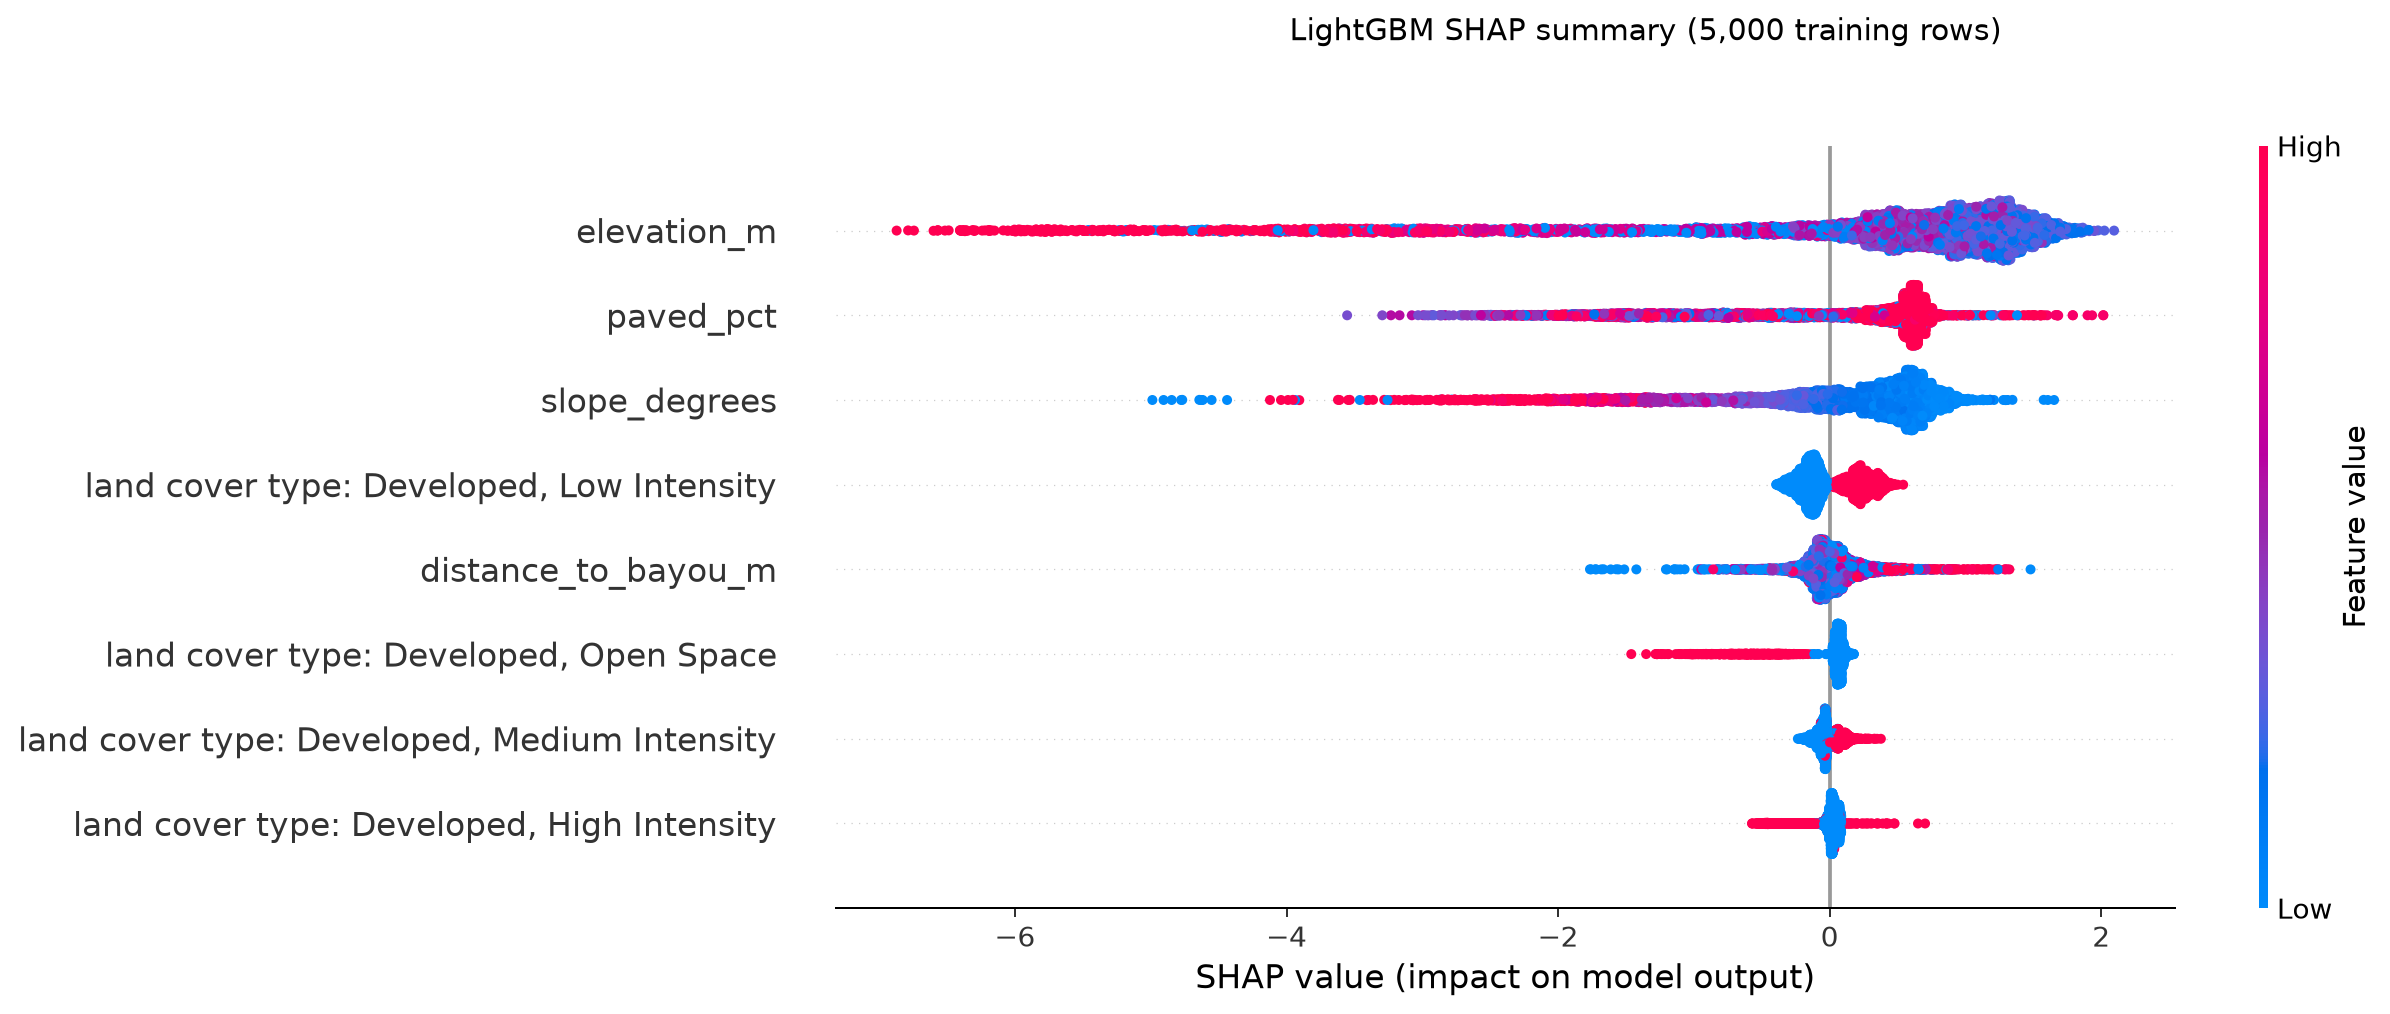

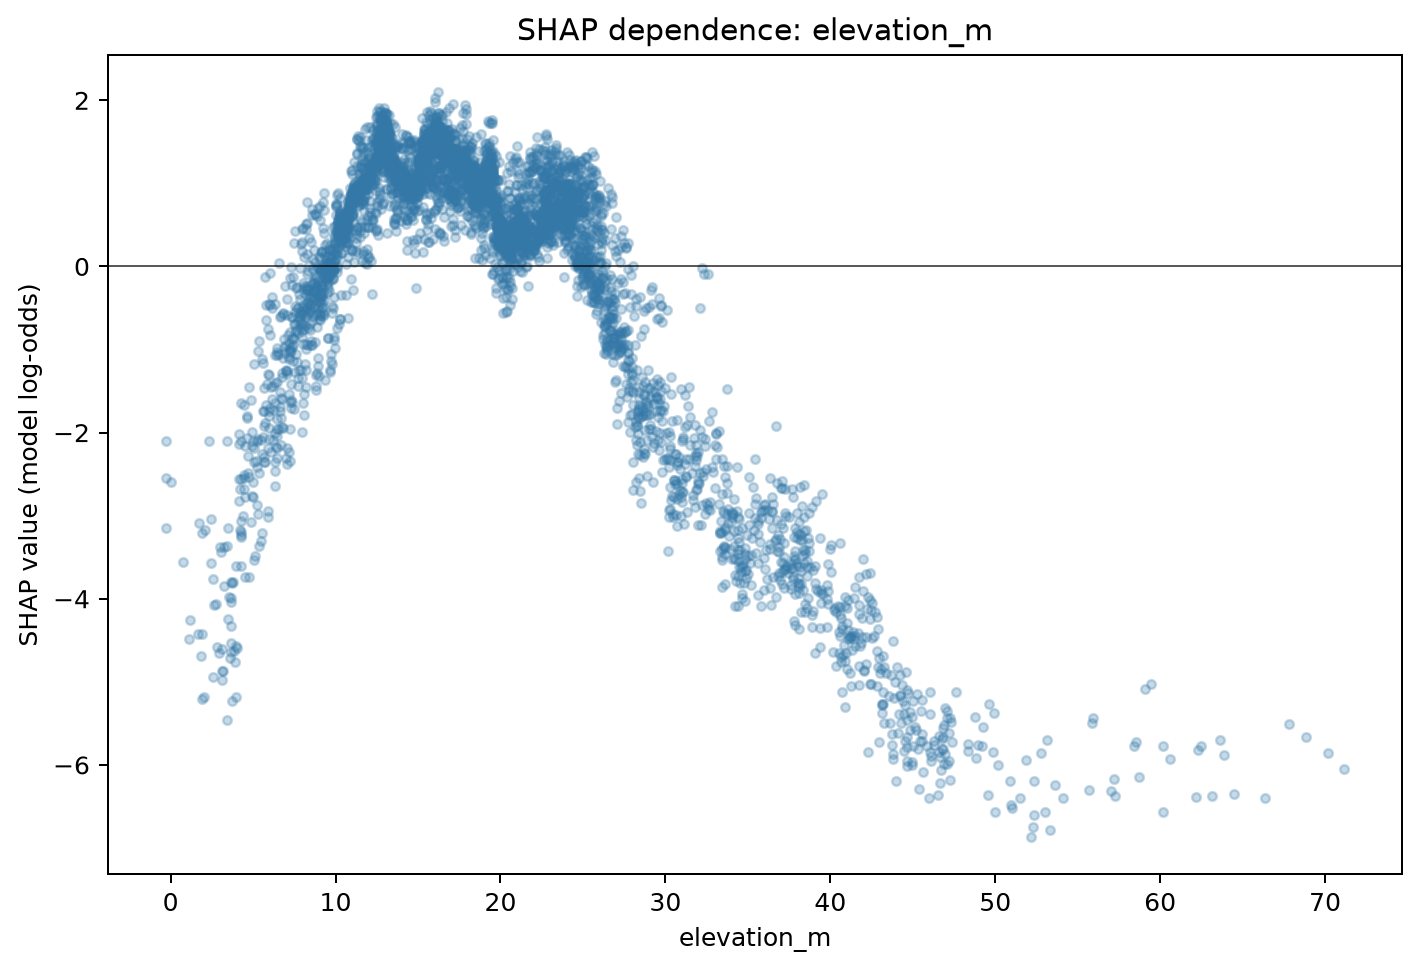

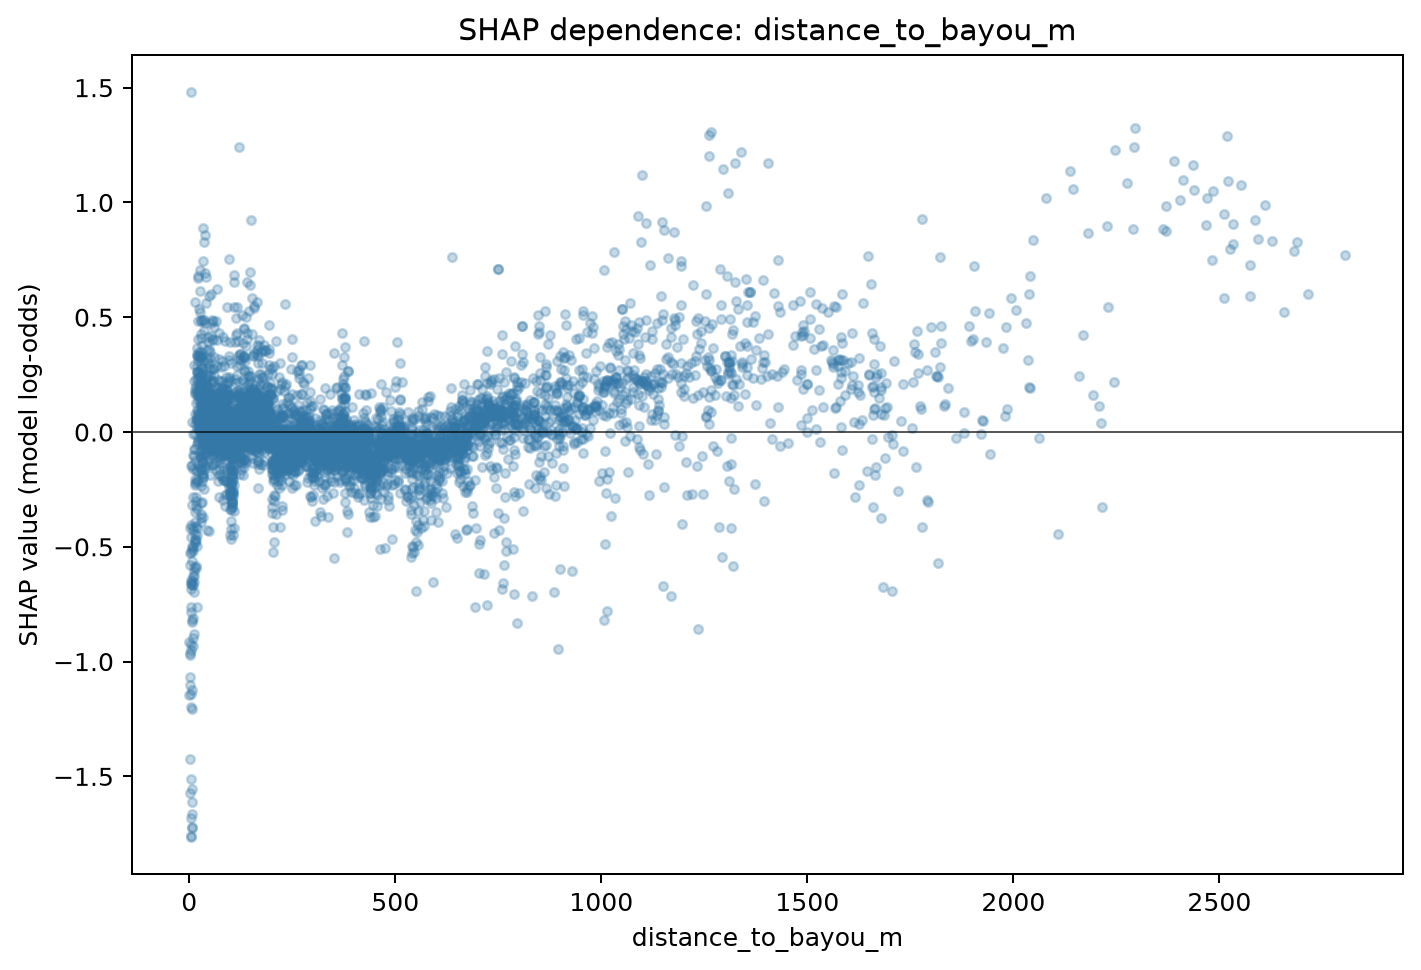

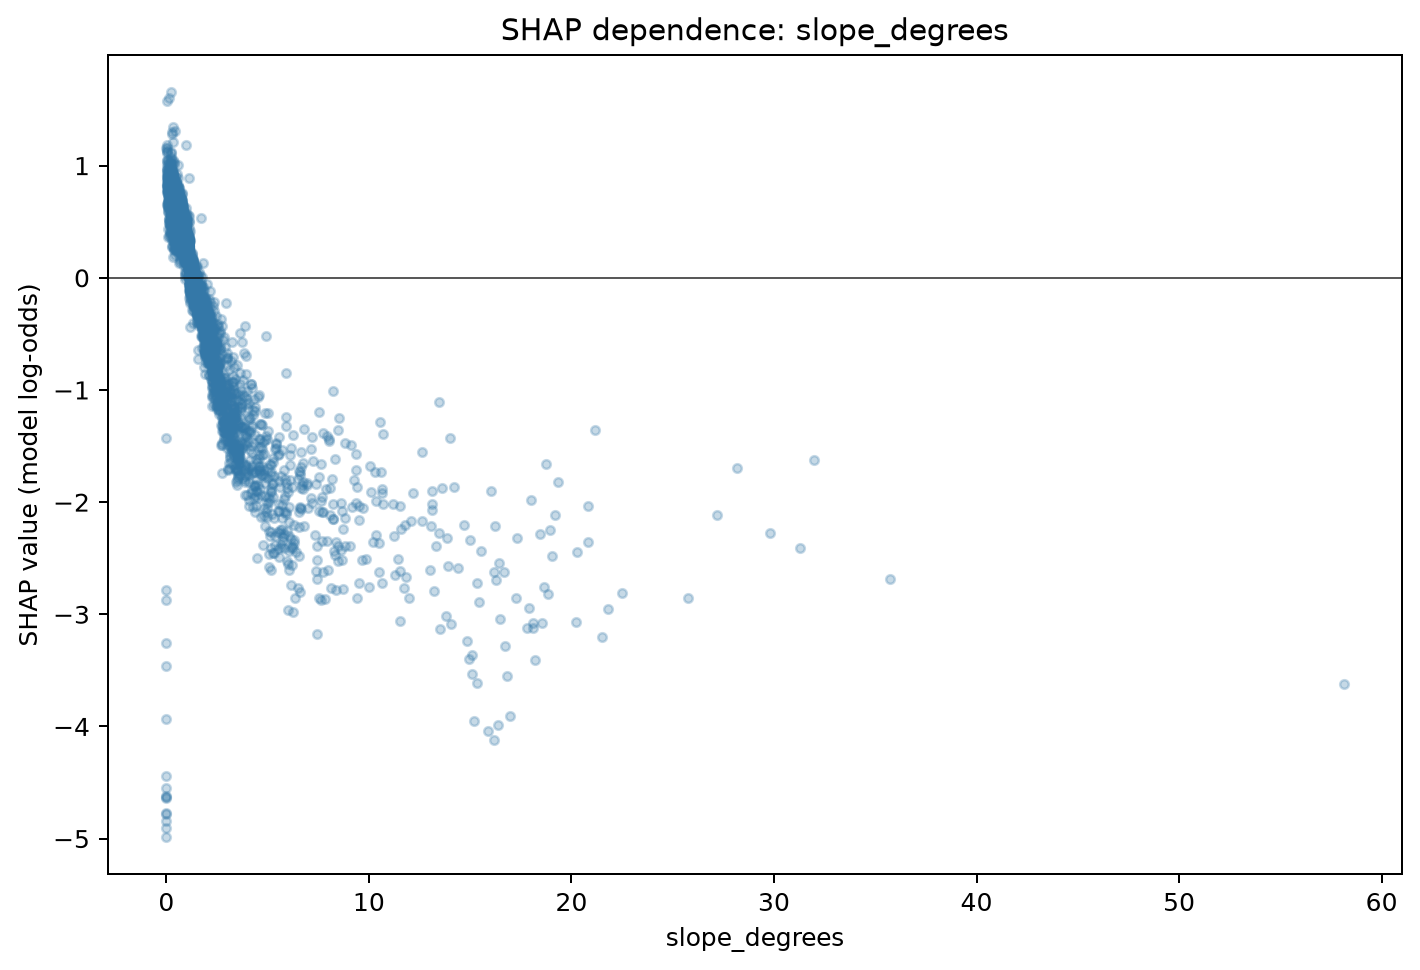

In [3]:
for filename in (
    "shap_lightgbm_beeswarm.png",
    "shap_dependence_elevation_m.png",
    "shap_dependence_distance_to_bayou_m.png",
    "shap_dependence_slope_degrees.png",
):
    display(Image(filename=str(FIGURES_DIR / filename)))

**My observations:** Elevation has the largest average SHAP effect, and its dependence plot changes direction across the observed range rather than following a straight-line pattern. The plots describe the model's learned patterns; they do not show that terrain causes flooding.

## 4. Three example predictions

The examples are selected deterministically from the 5,000-row sample: a flooded row predicted flooded, a non-flooded row predicted non-flooded, and a wrong prediction. Waterfall values explain each model score relative to the TreeExplainer baseline.

,example,row_index,latitude,longitude,y_true,y_pred_at_frozen_cutoff,y_prob
0,flooded_correct,52427,29.739338,-95.372041,1,1,0.981205
1,not_flooded_correct,61566,29.926458,-95.749353,0,0,0.000028
2,wrong_prediction,16356,30.068142,-95.239896,0,1,0.500096


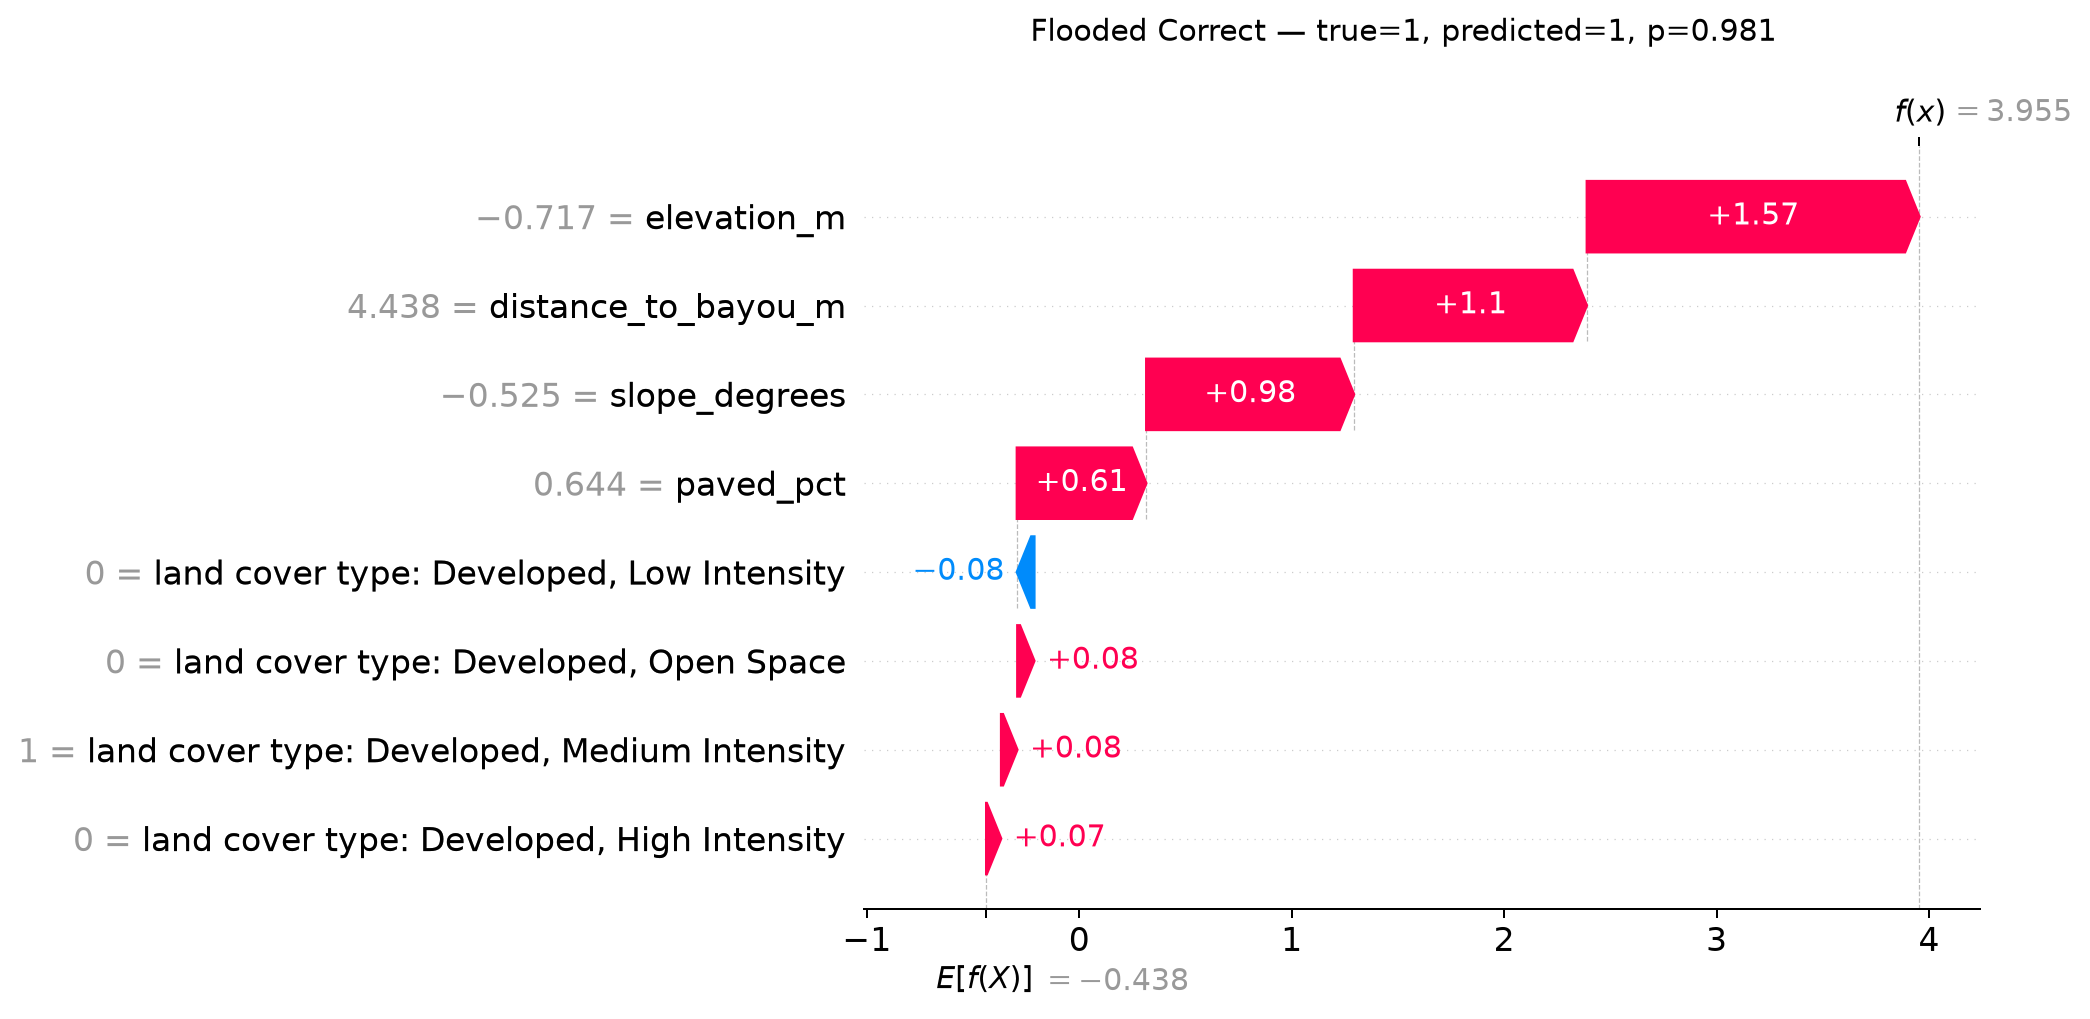

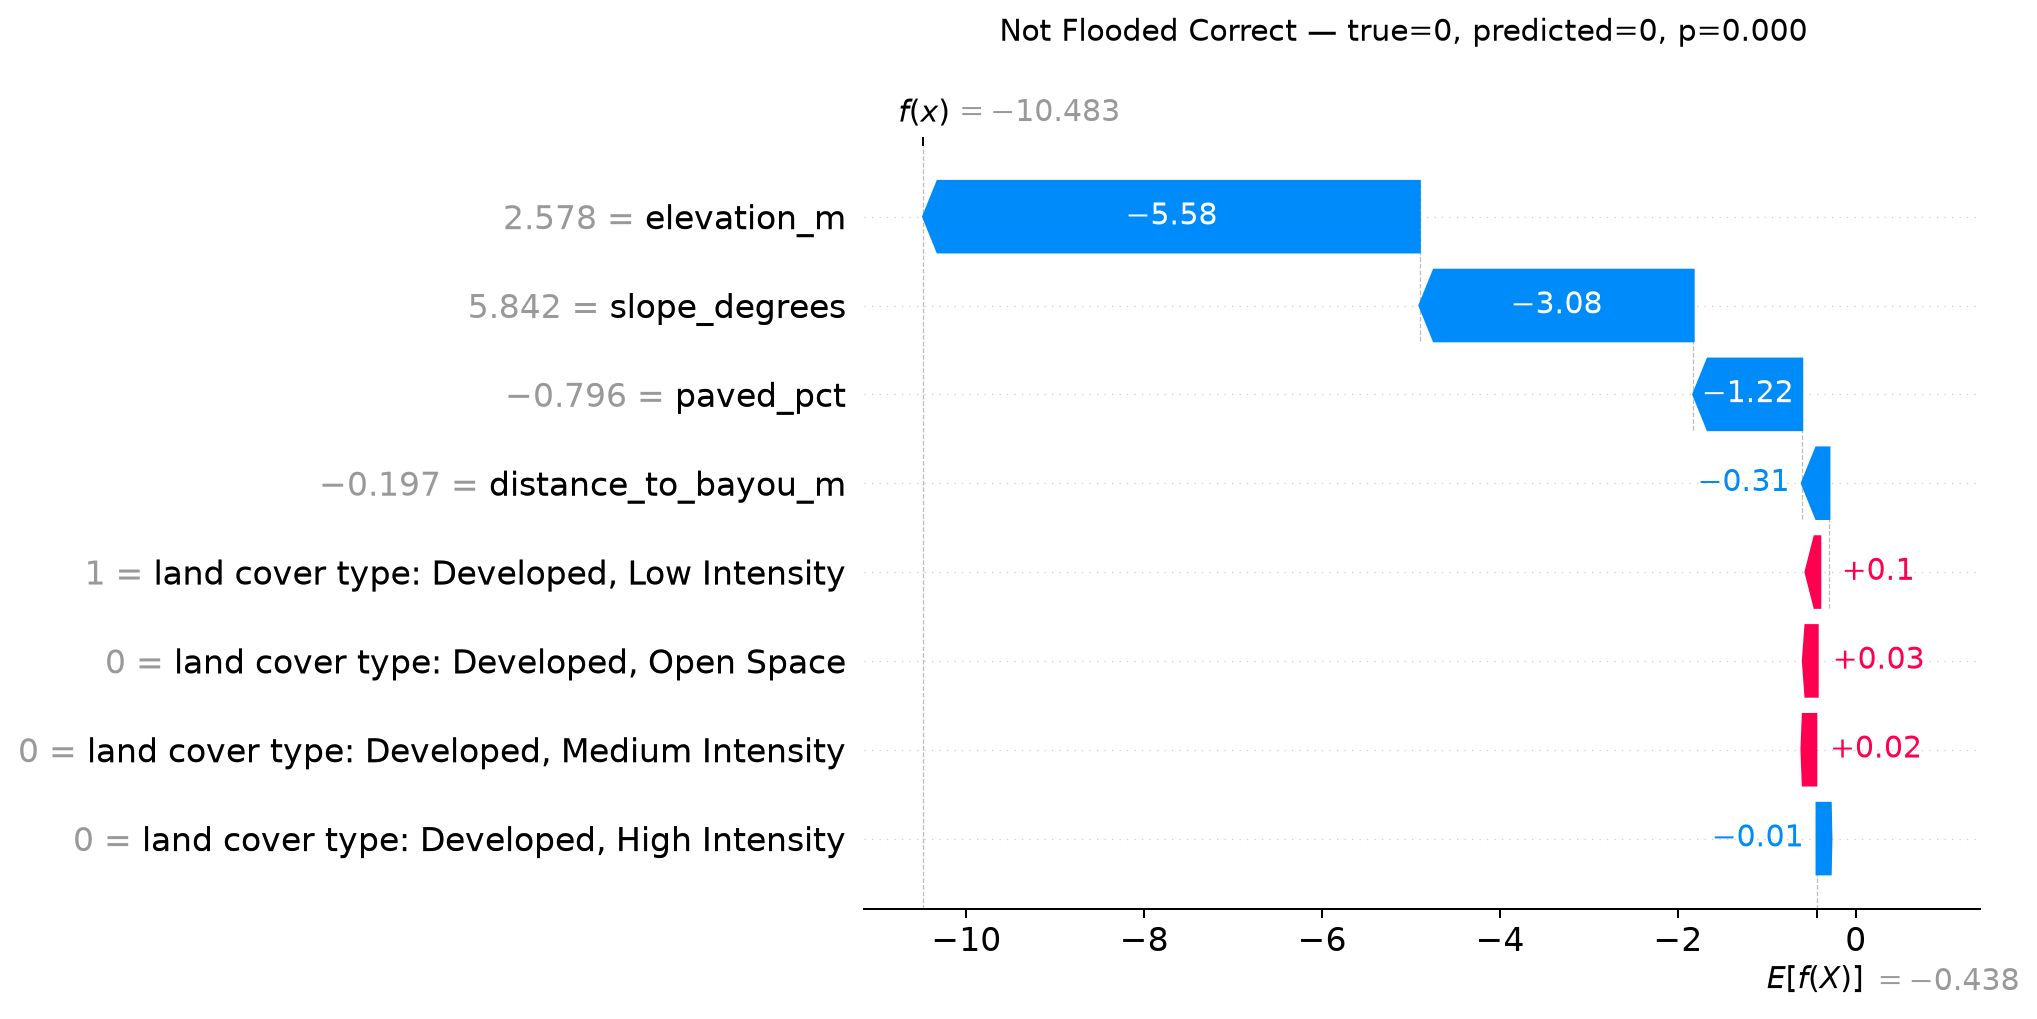

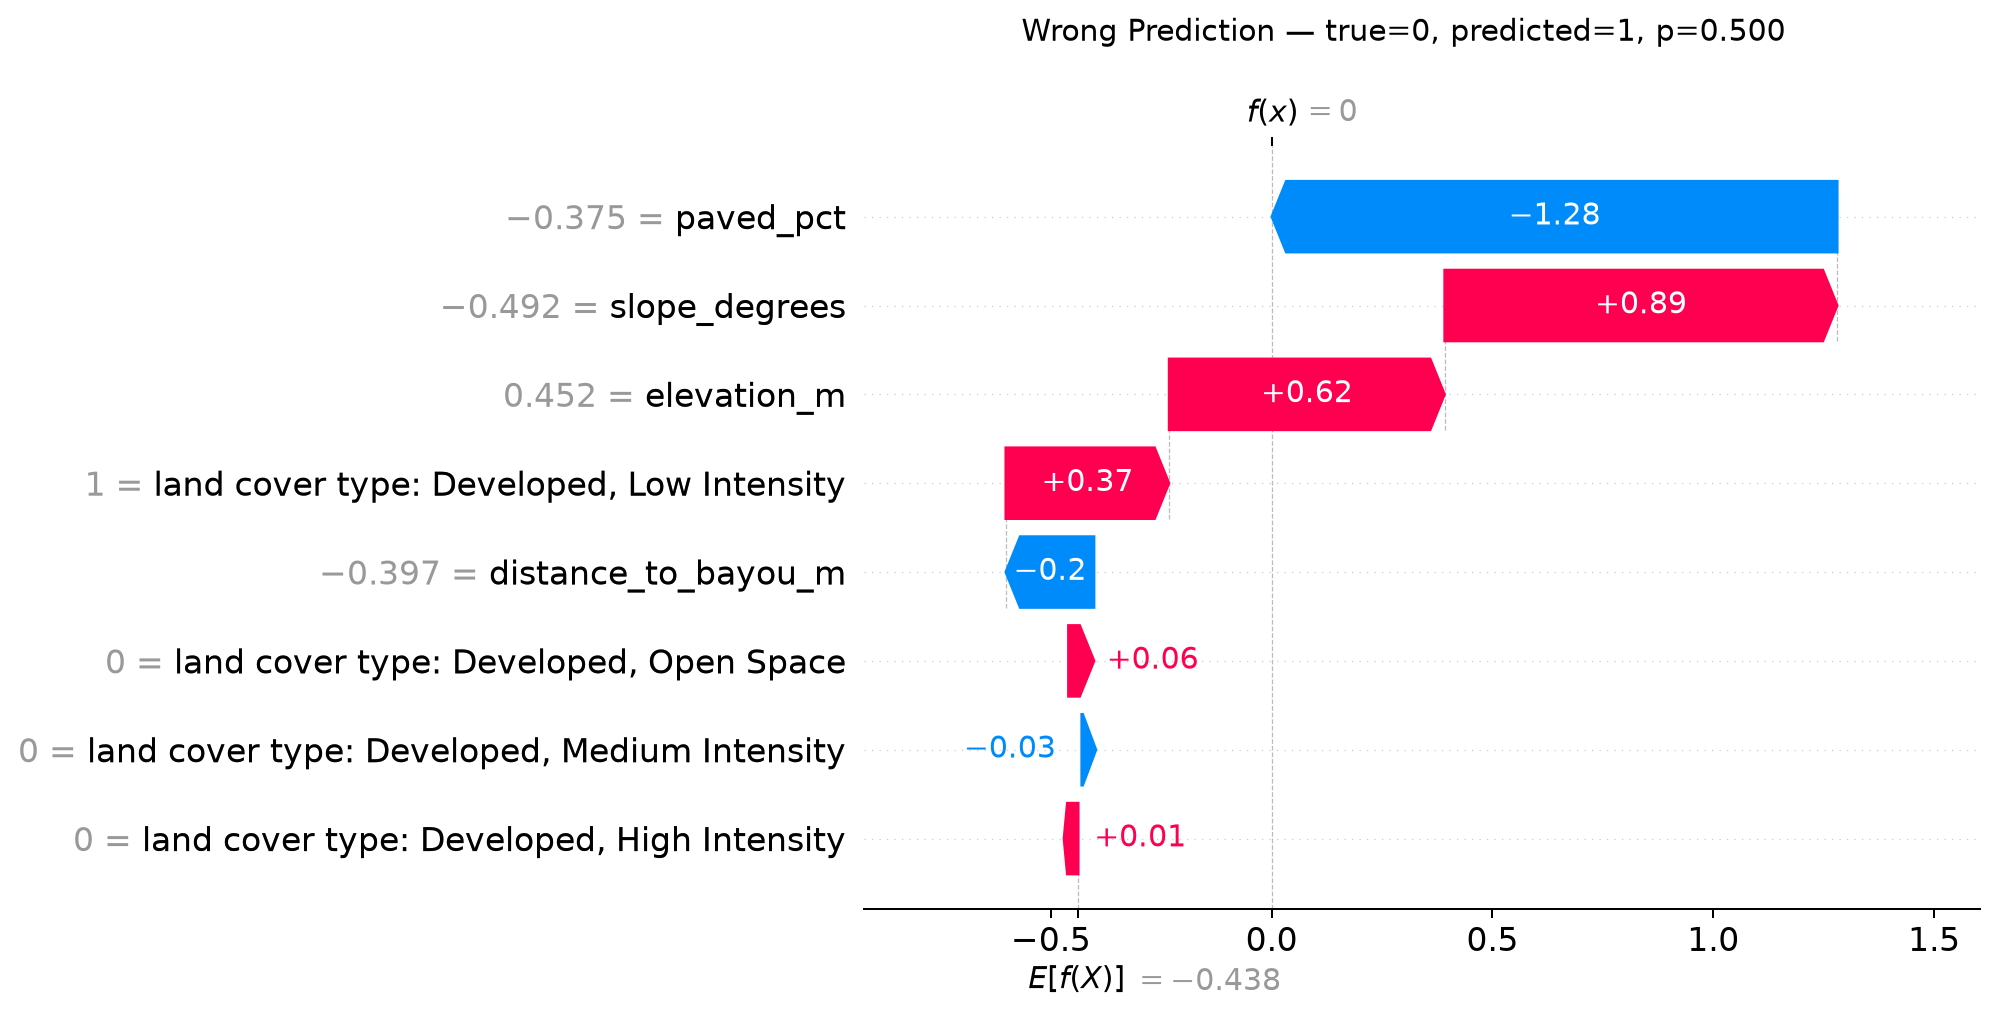

In [4]:
examples = pd.read_csv(EXAMPLES_PATH)
display(examples)
for example in examples["example"]:
    display(Image(filename=str(FIGURES_DIR / f"shap_waterfall_{example}.png")))

**My observations:** The flooded example (training row 52,427) was predicted flooded with probability 0.9812. The non-flooded example (row 61,566) had probability 0.000028. The wrong example (row 16,356) was actually non-flooded but was predicted flooded with probability 0.5001. These are in-sample examples, not independent performance estimates.

## 5. Limitation

SHAP shows what the model uses, not what causes flooding. `paved_pct` is really the share of the tract near major highways. The example predictions are in-sample, and should not be read as test performance.

**My observations:** SHAP shows what the model uses, not what causes flooding. `paved_pct` is really the share of the tract near major highways, so it should not be read as a general measure of pavement.